# Sales Analysis – Sample Superstore
**Dataset:** Sample Superstore (9,994 order lines, 21 columns) – US retail orders from 2014 to 2017 across Furniture, Office Supplies and Technology.

**Goal:** Understand which categories, regions, products, customers and discount levels drive sales and profit, and where the business loses money.

**Tools used:** Python, pandas, NumPy, Matplotlib, Seaborn, Plotly

**Dataset** Sample-superstore from kaggle; 
**Link of Dataset** www.kaggle.com/datasets/vivek468/superstore-dataset-final


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Dataset Loading 

In [2]:
#load the dataset
df = pd.read_csv(r'Sample_Superstore.csv', encoding='latin1')

# Data Exploration
* Checking structure of dataset
* Checking for missing values
* Handling missing values

In [3]:
print('Shape of dataset:', df.shape)
df.head()

Order of dataset: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
#information of table columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
#checking for missing values in colums
df.isna().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

# Data Cleaning

In [6]:
#since the country for all orders is Same i.e United States, so we not need that country column
df = df.drop(columns = 'Country')


In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [8]:
#since the order date and ship date is in str format, but should be in date format so we'll change it
df["Order Date"] = pd.to_datetime(df["Order Date"],format="%m/%d/%Y")

In [9]:
df["Ship Date"] = pd.to_datetime(df["Ship Date"],format="%m/%d/%Y")

# Exploratory Data Analysis(EDA)
* Sales & Profit Analysis
* Category Analysis
* Regional Analysis
* Product Analysis
* Customer and Segment Analysis
* Time Based Analysis
* Discount Analysis
* Statistical Analysis Using NumPy and pandas

# Sales & Profit Analysis

In [10]:
#total sales
df['Sales'].sum()

np.float64(2297200.8603)

In [11]:
#total Profit
df['Profit'].sum()

np.float64(286397.0217)

In [12]:
#total Quantity Sold
df['Quantity'].sum()

np.int64(37873)

In [13]:
#average Sales value
df['Sales'].mean()

np.float64(229.85800083049827)

In [14]:
#average profit per record
df['Profit'].mean()

np.float64(28.65689630778467)

In [15]:
#highest individual sale
df['Sales'].max()

np.float64(22638.48)

In [16]:
#lowest individual sale
df['Sales'].min()

np.float64(0.444)

In [17]:
#maximum profit date
df.loc[df['Profit'].idxmax(), ['Order Date', 'Product Name', 'Profit']]

Order Date                        2016-10-02 00:00:00
Product Name    Canon imageCLASS 2200 Advanced Copier
Profit                                       8399.976
Name: 6826, dtype: object

In [18]:
#minimum profit date
df.loc[df['Profit'].idxmin(), ['Order Date', 'Product Name', 'Profit']]

Order Date                            2016-11-25 00:00:00
Product Name    Cubify CubeX 3D Printer Double Head Print
Profit                                          -6599.978
Name: 7772, dtype: object

In [19]:
#total negative profit (loss)
(df['Profit']<0).sum()

np.int64(1871)

In [20]:
#percentage of records that are profitable
(df['Profit']>0).mean() * 100

np.float64(80.62837702621573)

# Visualization

Text(0.5, 1.0, 'Profit Vs Sales')

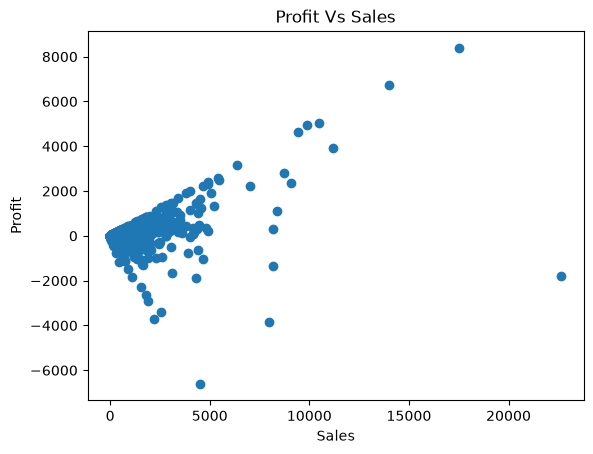

In [21]:
#Sales Vs Profit 
plt.scatter(df['Sales'], df['Profit'])
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.title('Profit Vs Sales')

# Key Insights from Sales & Profit
* Total Sales were approx 23 lakhs
* Total Profit is approx 2.86 lakhs
* Total Quantity Sold is 37873
* Average Sales per row is approx 229.86
* Average Profit per row is approx 28.65
* Highest & Lowest sale recorded are 22638.48 & 0.444 respectively
* Maximum Profit is recorded on 10/2/2016 of "Canon imageCLASS 2200 Advanced Copier" with profit of 8399.976
* Minimum Profit is recorded on 11/25/2016 of "Cubify CubeX 3D Printer Double Head Print" with loss of 6599.978

# Category Analysis

In [22]:
#product category that generates highest total sales
df.groupby('Category')['Sales'].sum().sort_values(ascending = False).head(1)

Category
Technology    836154.033
Name: Sales, dtype: float64

In [23]:
#product category that generates highest total profit
df.groupby('Category')['Profit'].sum().sort_values(ascending = False).head(1)

Category
Technology    145454.9481
Name: Profit, dtype: float64

In [24]:
#category that has lowest total profit
df.groupby('Category')['Profit'].sum().sort_values(ascending = True).head(1)

Category
Furniture    18451.2728
Name: Profit, dtype: float64

In [25]:
#total quantity sold in each category
df.groupby('Category')['Quantity'].sum()

Category
Furniture           8028
Office Supplies    22906
Technology          6939
Name: Quantity, dtype: int64

In [26]:
#category that has highest average discount
df.groupby("Category")["Discount"].mean().sort_values(ascending = False).head(1)

Category
Furniture    0.173923
Name: Discount, dtype: float64

# Visualization

Text(0, 0.5, 'Sales')

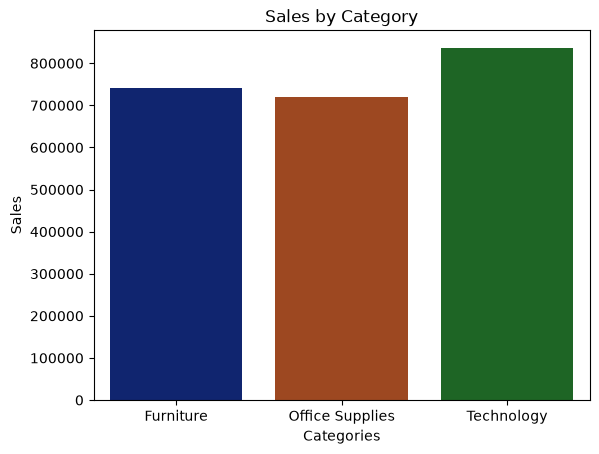

In [27]:
#Total Sales by category
cat_sales = df.groupby('Category')['Sales'].sum()
sns.barplot(x=cat_sales.index, y=cat_sales.values, hue=cat_sales.index, palette='dark', legend=False)
plt.title('Sales by Category')
plt.xlabel('Categories')
plt.ylabel('Sales')

Text(0, 0.5, 'Profit')

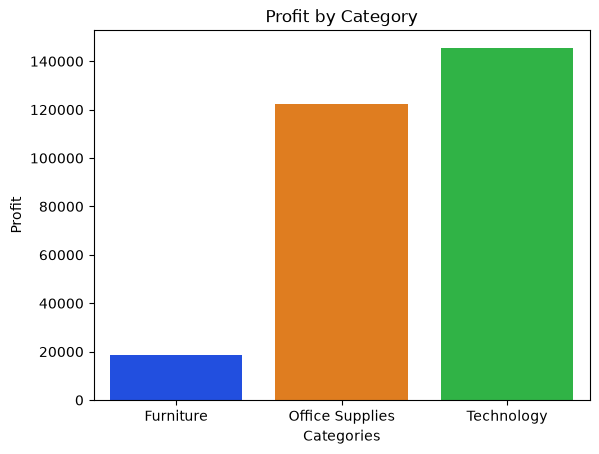

In [28]:
#total profit by category
cat_profit = df.groupby('Category')['Profit'].sum()
sns.barplot(x=cat_profit.index, y=cat_profit.values, hue=cat_profit.index, palette='bright', legend=False)
plt.title('Profit by Category')
plt.xlabel('Categories')
plt.ylabel('Profit')

# Key Insights from Category Analysis
* Technology generated highest sale and profit
* Furniture generated least total profit
* Office supplies has highest quantity sold
* Furniture offers highest average discount

# Regional Analysis

In [29]:
#region that generate highest sales
df.groupby('Region')['Sales'].sum().sort_values(ascending =False).head(1)

Region
West    725457.8245
Name: Sales, dtype: float64

In [30]:
#region that generate highest profit
df.groupby('Region')['Profit'].sum().sort_values(ascending =False).head(1)

Region
West    108418.4489
Name: Profit, dtype: float64

In [31]:
#region that has lowest profit
df.groupby('Region')['Profit'].sum().sort_values(ascending =True).head(1)

Region
Central    39706.3625
Name: Profit, dtype: float64

In [32]:
#total quantity sold in each region
df.groupby('Region')['Quantity'].sum()

Region
Central     8780
East       10618
South       6209
West       12266
Name: Quantity, dtype: int64

In [33]:
#category that performs best in each region
df.groupby(['Region', 'Category'])[['Sales', 'Profit']].sum().round(0)

Sales   Profit
Region  Category                          
Central Furniture        163797.0  -2871.0
        Office Supplies  167026.0   8880.0
        Technology       170416.0  33697.0
East    Furniture        208291.0   3046.0
        Office Supplies  205516.0  41015.0
        Technology       264974.0  47462.0
South   Furniture        117299.0   6771.0
        Office Supplies  125651.0  19986.0
        Technology       148772.0  19992.0
West    Furniture        252613.0  11505.0
        Office Supplies  220853.0  52610.0
        Technology       251992.0  44304.0

# Visualization

Text(0, 0.5, 'Sales')

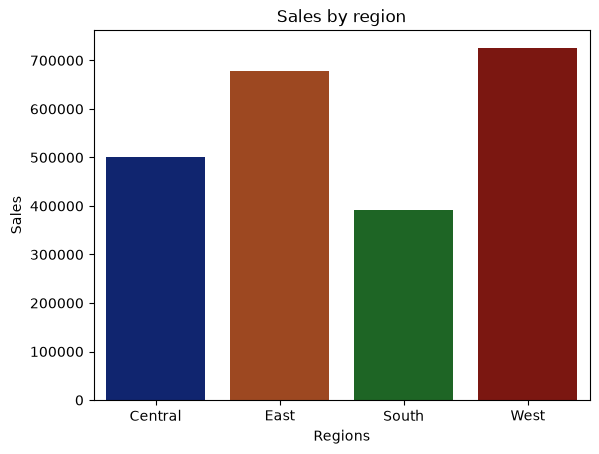

In [34]:
#Total Sales by Region
reg_sales = df.groupby('Region')['Sales'].sum()
sns.barplot(x=reg_sales.index, y=reg_sales.values, hue=reg_sales.index, palette='dark', legend=False)
plt.title('Sales by region')
plt.xlabel('Regions')
plt.ylabel('Sales')

Text(0, 0.5, 'Profit')

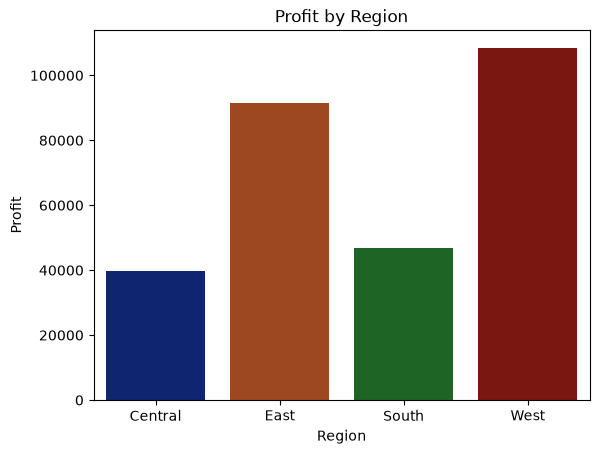

In [35]:
#Total Profit by Region
reg_profit = df.groupby('Region')['Profit'].sum()
sns.barplot(x=reg_profit.index, y=reg_profit.values, hue=reg_profit.index, palette='dark', legend=False)
plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Profit')

# Product Anlysis

In [36]:
#product that generate highest sales
df.groupby('Product Name')['Sales'].sum().sort_values(ascending = False).head(1)

Product Name
Canon imageCLASS 2200 Advanced Copier    61599.824
Name: Sales, dtype: float64

In [37]:
#product that generate highest total profit
df.groupby('Product Name')['Profit'].sum().sort_values(ascending = False).head(1)

Product Name
Canon imageCLASS 2200 Advanced Copier    25199.928
Name: Profit, dtype: float64

In [38]:
#product that is generating most loss
df.groupby('Product Name')['Profit'].sum().sort_values(ascending =True).head(1)

Product Name
Cubify CubeX 3D Printer Double Head Print   -8879.9704
Name: Profit, dtype: float64

In [39]:
#product with highest quantity sold
df.groupby('Product Name')['Quantity'].sum().sort_values(ascending =False).head(1)

Product Name
Staples    215
Name: Quantity, dtype: int64

# Visualisation

C:\Users\user\AppData\Local\Temp\ipykernel_8408\3724357451.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= topsale.values, y=topsale.index, palette = 'bright')


Text(0, 0.5, 'Top 10 Products')

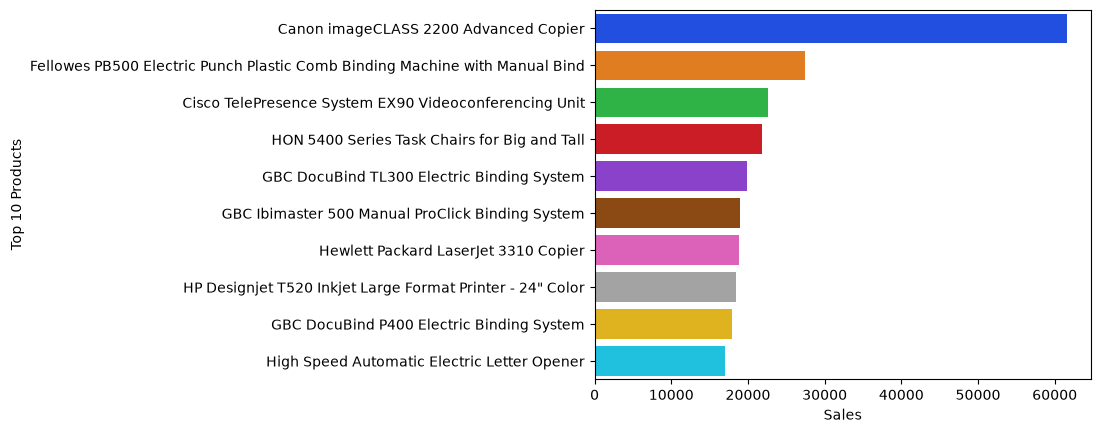

In [40]:
#top 10 product by sales
topsale = df.groupby('Product Name')['Sales'].sum().sort_values(ascending = False).head(10)
sns.barplot(x= topsale.values, y=topsale.index, palette = 'bright')
plt.xlabel('Sales')
plt.ylabel('Top 10 Products')

C:\Users\user\AppData\Local\Temp\ipykernel_8408\2093735549.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= topprofit.values, y= topprofit.index, palette ='bright')


Text(0, 0.5, 'Top 10 Products')

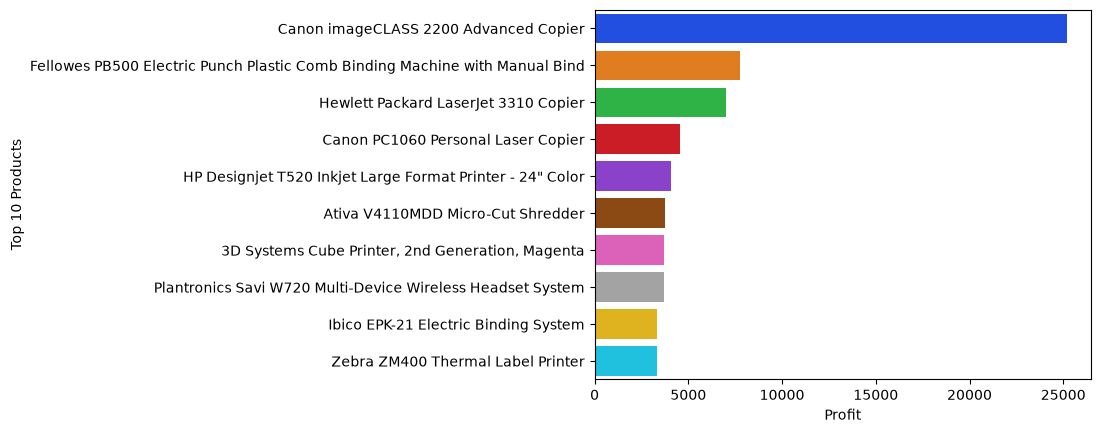

In [41]:
#top 10 products by profit
topprofit = df.groupby('Product Name')['Profit'].sum().sort_values(ascending = False).head(10)
sns.barplot(x= topprofit.values, y= topprofit.index, palette ='bright')
plt.xlabel('Profit')
plt.ylabel('Top 10 Products')

Text(0, 0.5, 'Top 10 Products(in Loss)')

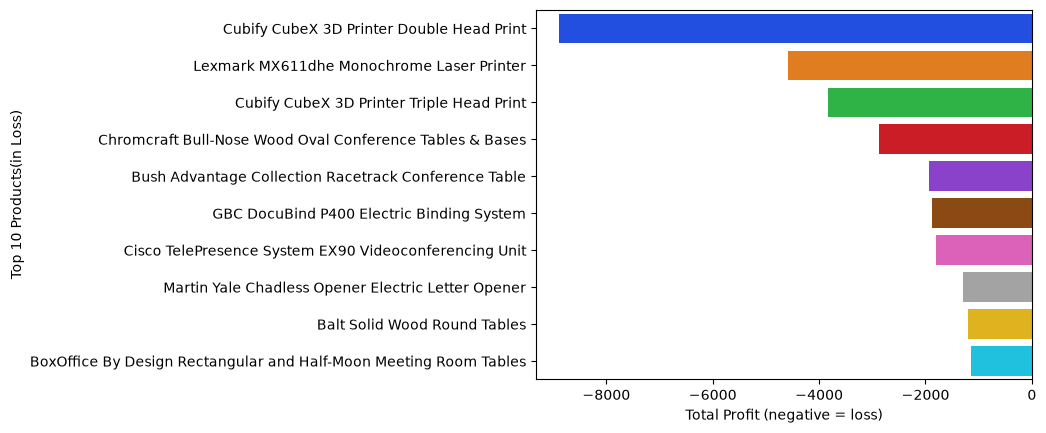

In [42]:
#top 10 products by loss
toploss = df.groupby('Product Name')['Profit'].sum().sort_values(ascending = True).head(10)
sns.barplot(x= toploss.values, y=toploss.index, hue=toploss.index, palette='bright', legend=False)
plt.xlabel('Total Profit (negative = loss)')
plt.ylabel('Top 10 Products(in Loss)')

C:\Users\user\AppData\Local\Temp\ipykernel_8408\3686767077.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= topsold.values, y= topsold.index, palette ='bright')


Text(0, 0.5, 'Top 10 Products')

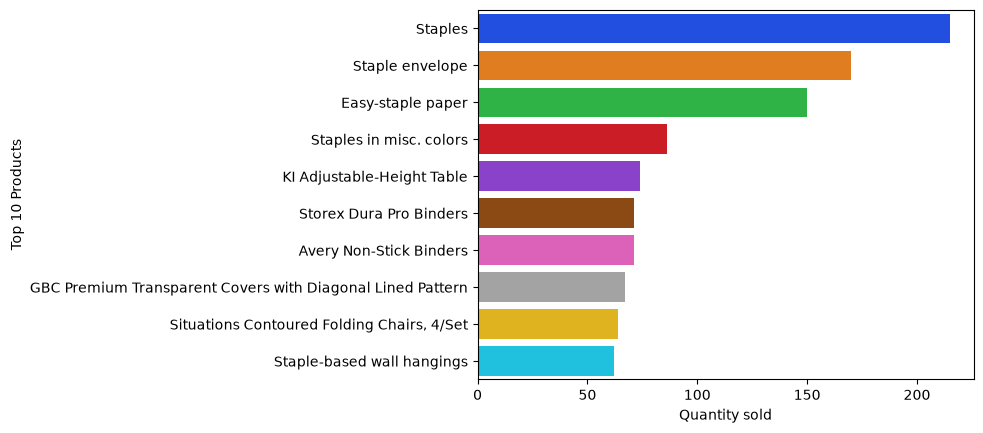

In [43]:
#top10 product with quantity
topsold = df.groupby('Product Name')['Quantity'].sum().sort_values(ascending = False).head(10)
sns.barplot(x= topsold.values, y= topsold.index, palette ='bright')
plt.xlabel('Quantity sold')
plt.ylabel('Top 10 Products')

# Key Insights from Product Analysis
* Canon imageCLASS 2200 Advanced Copier leads both total sales (61,599.82) and total profit (25,199.93)
* Highest Quantity sold is of staples(215)
* Cubify CubeX 3D Printer Double Head Print made total loss of 8,879.97
* High sales do not always mean high profit

# Customer & Segment Analysis

In [44]:
#top 10 customers that generated highest sales
df.groupby('Customer Name')['Sales'].sum().sort_values(ascending = False).head(10)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

In [45]:
#top 10 customers that generated highest profit
df.groupby('Customer Name')['Profit'].sum().sort_values(ascending = False).head(10)

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64

In [46]:
#top 10 customers that have lowest total profit
df.groupby('Customer Name')['Profit'].sum().sort_values(ascending = True).head(10)

Customer Name
Cindy Stewart      -6626.3895
Grant Thornton     -4108.6589
Luke Foster        -3583.9770
Sharelle Roach     -3333.9144
Henry Goldwyn      -2797.9635
Nathan Cano        -2204.8072
Sean Braxton       -2082.7451
Sean Miller        -1980.7393
Christine Phan     -1850.3029
Natalie Fritzler   -1695.9714
Name: Profit, dtype: float64

In [47]:
#customer that purchased highest quantity
df.groupby('Customer Name')['Quantity'].sum().sort_values(ascending = False).head(10)

Customer Name
Jonathan Doherty       150
William Brown          146
John Lee               143
Paul Prost             138
Steven Cartwright      133
Emily Phan             124
Chloris Kastensmidt    122
Cassandra Brandow      122
Edward Hooks           120
Matt Abelman           117
Name: Quantity, dtype: int64

In [48]:
#segment generates the highest sales and profit
df.groupby('Segment').agg(Total_Sales =('Sales', 'sum'),
                         Total_profit = ('Profit', 'sum'),
                         Total_Quantity =('Quantity', 'sum'),
                         Average_Discount= ('Discount', 'mean'),
                         Total_orders =('Order ID', 'nunique')).round(1)

,Total_Sales,Total_profit,Total_Quantity,Average_Discount,Total_orders
Segment,,,,,
Consumer,1161401.3,134119.2,19521,0.2,2586
Corporate,706146.4,91979.1,11608,0.2,1514
Home Office,429653.1,60298.7,6744,0.1,909


# Visualisation

C:\Users\user\AppData\Local\Temp\ipykernel_8408\3041902987.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= top_sales.values, y=top_sales.index, palette='bright')


Text(0, 0.5, 'Customer Name')

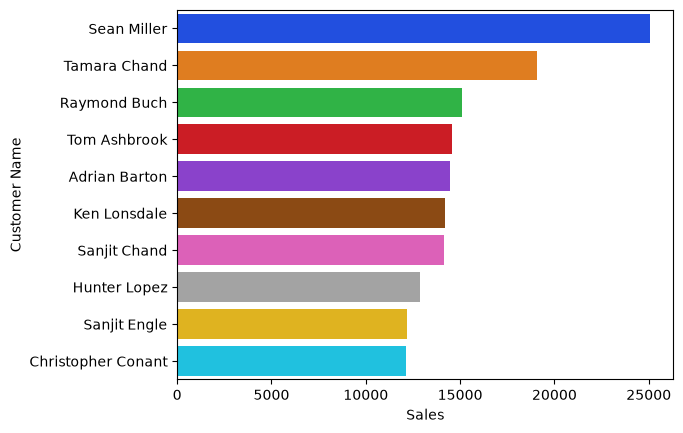

In [49]:
#top 10 customers by sale
top_sales= df.groupby('Customer Name')['Sales'].sum().sort_values(ascending = False).head(10)
sns.barplot(x= top_sales.values, y=top_sales.index, palette='bright')
plt.xlabel('Sales')
plt.ylabel('Customer Name')

C:\Users\user\AppData\Local\Temp\ipykernel_8408\3328981404.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= top_sales.values, y=top_sales.index, palette='bright')


Text(0, 0.5, 'Customer Name')

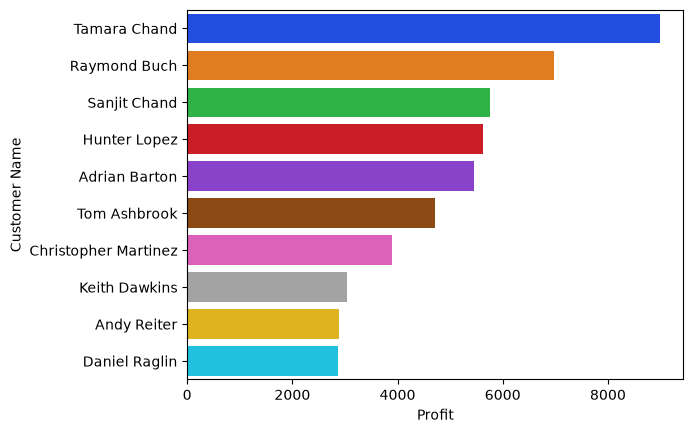

In [50]:
#top 10 customers by Profit
top_sales= df.groupby('Customer Name')['Profit'].sum().sort_values(ascending = False).head(10)
sns.barplot(x= top_sales.values, y=top_sales.index, palette='bright')
plt.xlabel('Profit')
plt.ylabel('Customer Name')

C:\Users\user\AppData\Local\Temp\ipykernel_8408\1380573934.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segment_sales.index, y=segment_sales.values, palette ='bright')


Text(0, 0.5, 'Sales')

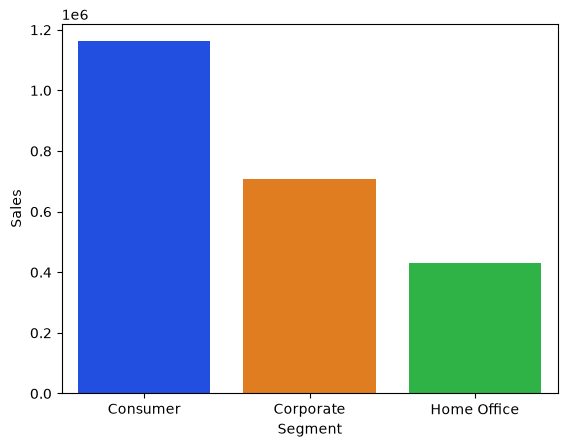

In [51]:
#sales by customer segment
segment_sales = df.groupby("Segment")["Sales"].sum()
sns.barplot(x=segment_sales.index, y=segment_sales.values, palette ='bright')
plt.xlabel('Segment')
plt.ylabel('Sales')

Text(0, 0.5, 'Profit')

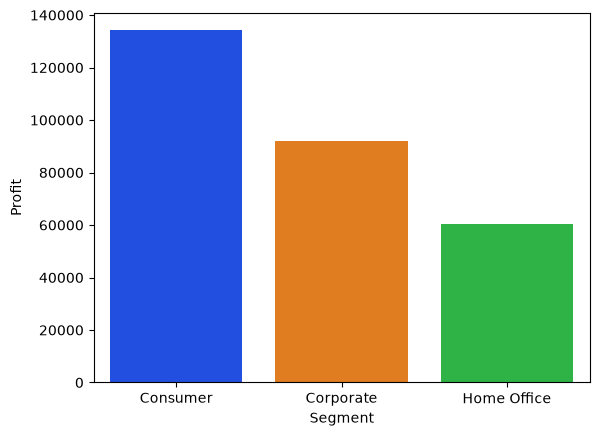

In [52]:
#Profit by customer segment
segment_profit = df.groupby("Segment")["Profit"].sum()
sns.barplot(x=segment_profit.index, y=segment_profit.values, hue=segment_profit.index, palette='bright', legend=False)
plt.xlabel('Segment')
plt.ylabel('Profit')

# Key Insights from Customer & Segment Anlysis
* Sean Miller generated highest total sales of 25,043.05
* Tamara Chand generated highest total profit of 8,981.32
* Cindy Stewart recorded a total profit of -6,626.39
* Consumer generated the highest total sales (1,161,401.34) and total profit (134,119.21), being the best segment by total performance
* Home Office generated an average profit of 66.34 per order which is highest

# Time Bases Anlaysis

In [53]:
#firstly we'll extract year, month and month name, order date from order date
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()


* Yearly Analysis

In [54]:
#full yearwise analysis
df.groupby('Order Year').agg(Total_Sales =('Sales', 'sum'),
                            Total_Profit =('Profit', 'sum'),
                            Total_Quantity=('Quantity', 'sum')).round(1)

,Total_Sales,Total_Profit,Total_Quantity
Order Year,,,
2014,484247.5,49544.0,7581
2015,470532.5,61618.6,7979
2016,609205.6,81795.2,9837
2017,733215.3,93439.3,12476


In [55]:
#which year has highest sale
df.groupby('Order Year')['Sales'].sum().sort_values(ascending =False).head(1)

Order Year
2017    733215.2552
Name: Sales, dtype: float64

In [56]:
#which year had highest profit
df.groupby('Order Year')['Profit'].sum().sort_values(ascending =False).head(1)

Order Year
2017    93439.2696
Name: Profit, dtype: float64

* Monthly Analysis

In [57]:
#full month wise analysis
df.groupby('Month Name').agg(Total_Sales =('Sales', 'sum'),
                            Total_Profit =('Profit', 'sum'),
                            Total_Quantity=('Quantity', 'sum')).round(1)

,Total_Sales,Total_Profit,Total_Quantity
Month Name,,,
April,137762.1,11587.4,2447
August,159044.1,21776.9,2784
December,325293.5,43369.2,5419
February,59751.3,10294.6,1067
January,94924.8,9134.4,1475
July,147238.1,13832.7,2705
June,152718.7,21285.8,2680
March,205005.5,28594.7,2564
May,155028.8,22411.3,2791


In [58]:
#which month has highest sales
df.groupby('Month Name')['Sales'].sum().sort_values(ascending =False).head(1)

Month Name
November    352461.071
Name: Sales, dtype: float64

In [59]:
#which month has lowest profit
df.groupby('Month Name')['Profit'].sum().sort_values(ascending =True).head(1)

Month Name
January    9134.4461
Name: Profit, dtype: float64

# Visualisation

Text(0.5, 1.0, 'Yearly Sales Trend')

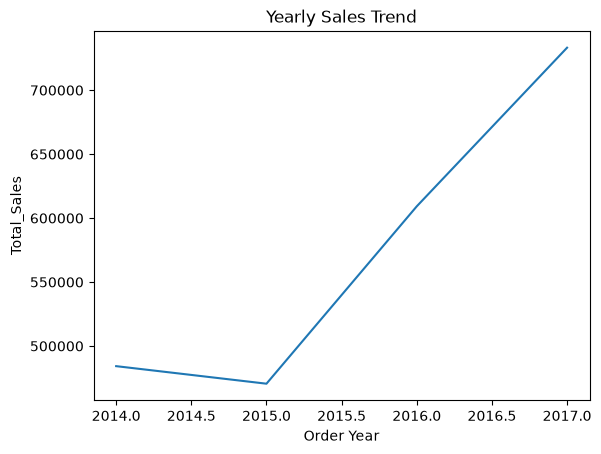

In [60]:
yearly_analysis= df.groupby('Order Year').agg(Total_Sales =('Sales', 'sum'),
                            Total_Profit =('Profit', 'sum'),
                            Total_Quantity=('Quantity', 'sum')).round(1)
sns.lineplot(x= yearly_analysis.index, y= yearly_analysis['Total_Sales'])
plt.title("Yearly Sales Trend")

Text(0.5, 1.0, 'Yearly Profit Trend')

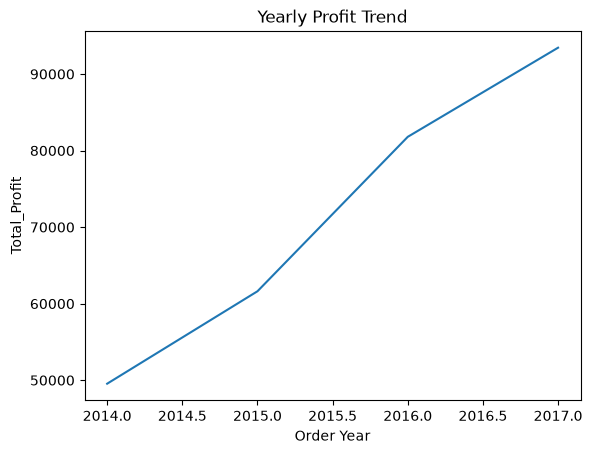

In [61]:
sns.lineplot(x= yearly_analysis.index, y=yearly_analysis['Total_Profit'])
plt.title("Yearly Profit Trend")

C:\Users\user\AppData\Local\Temp\ipykernel_8408\527753046.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=monthly_analysis.index, x= monthly_analysis['Total_Sales'], palette = 'bright')


Text(0.5, 1.0, 'Monthly Sales Trend')

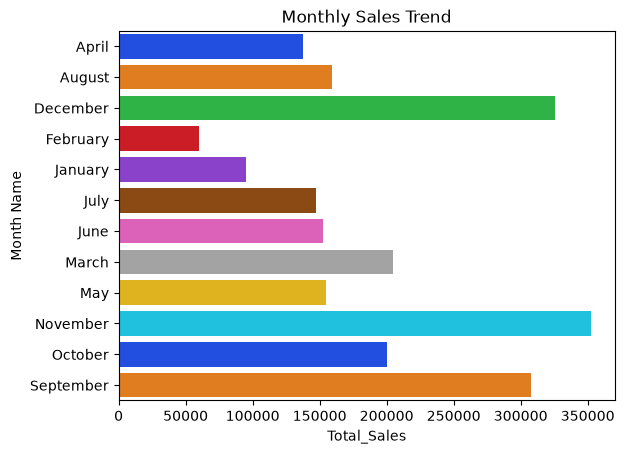

In [62]:
monthly_analysis =df.groupby('Month Name').agg(Total_Sales =('Sales', 'sum'),
                            Total_Profit =('Profit', 'sum'),
                            Total_Quantity=('Quantity', 'sum')).round(1)
sns.barplot(y=monthly_analysis.index, x= monthly_analysis['Total_Sales'], palette = 'bright')
plt.title("Monthly Sales Trend")

C:\Users\user\AppData\Local\Temp\ipykernel_8408\3164831163.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=monthly_analysis.index, x= monthly_analysis['Total_Profit'], palette = 'bright')


Text(0.5, 1.0, 'Monthly Profit Trend')

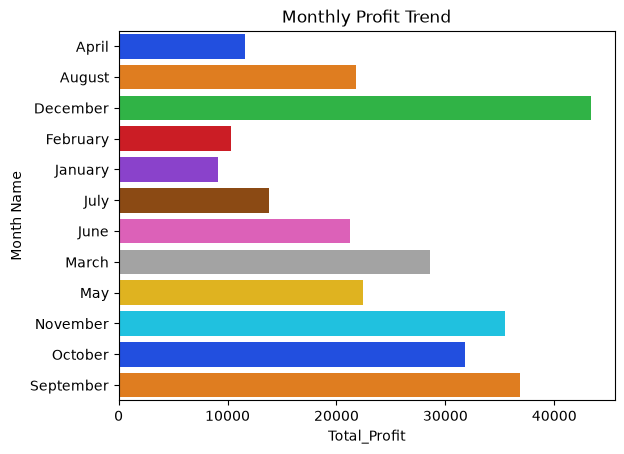

In [63]:
sns.barplot(y=monthly_analysis.index, x= monthly_analysis['Total_Profit'], palette = 'bright')
plt.title("Monthly Profit Trend")

Text(0.5, 1.0, 'Sales Heatmap')

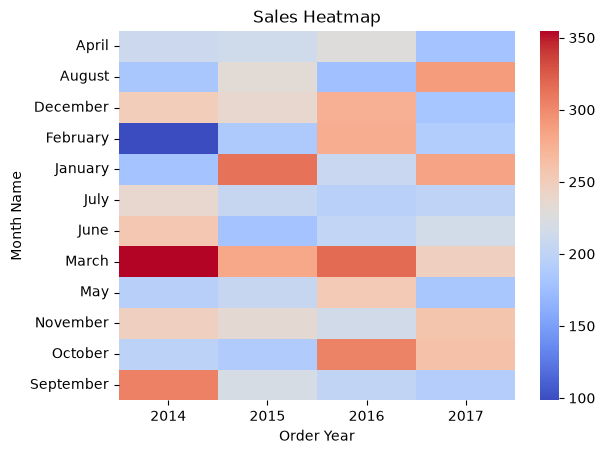

In [91]:
#pivot table heatmap
pvt= df.pivot_table(values = 'Sales', columns = 'Order Year', index = 'Month Name')
sns.heatmap(pvt, cmap='coolwarm')
plt.title('Sales Heatmap')

Text(0.5, 1.0, 'Profit Heatmap')

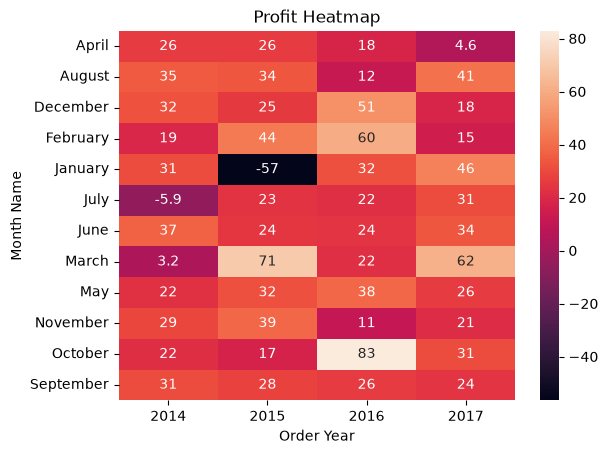

In [89]:
pvt1= df.pivot_table(values = 'Profit', columns = 'Order Year', index = 'Month Name')
sns.heatmap(pvt1, annot=True)
plt.title('Profit Heatmap')

# Key Insights from Time Analysis
* 2017 recorded the highest total sales of 733,215.26 and total profit of 93,439.27
* November recorded highest total sales across all four years
* December generated the highest total profit of 43,369.19
*  February recorded the lowest total sales of 59,751.25

# Discount Analysis

In [66]:
#distinct discount levels in the dataset
df['Discount'].unique()*100

array([ 0., 45., 20., 80., 30., 50., 70., 60., 32., 10., 40., 15.])

In [86]:
#total sales, profit, and quantity for each discount level
discount_analysis= df.groupby('Discount').agg(Total_Sales =('Sales', 'sum'),
                                             Total_profit= ('Profit', 'sum'),
                                             Total_quantity=('Quantity', 'sum'),
                                             No_of_records=('Discount', 'size'))
discount_analysis.round(2)

,Total_Sales,Total_profit,Total_quantity,No_of_records
Discount,,,,
0.00,1087908.47,320987.60,18267,4798
0.10,54369.35,9029.18,373,94
0.15,27558.52,1418.99,198,52
0.20,764594.37,90337.31,13660,3657
0.30,103226.66,-10369.28,849,227
0.32,14493.46,-2391.14,105,27
0.40,116417.78,-23057.05,786,206
0.45,5484.97,-2493.11,45,11
0.50,58918.54,-20506.43,241,66


In [68]:
#which discount level has highest profit
df.groupby('Discount')['Profit'].sum().sort_values(ascending =False).head(1)

Discount
0.0    320987.6032
Name: Profit, dtype: float64

In [69]:
#how does avg profit change with discount
df.groupby('Discount')['Profit'].mean()

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64

# Visualisation

C:\Users\user\AppData\Local\Temp\ipykernel_8408\2722792130.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= discount_analysis.index, y= discount_analysis['Total_profit'], palette ='bright')


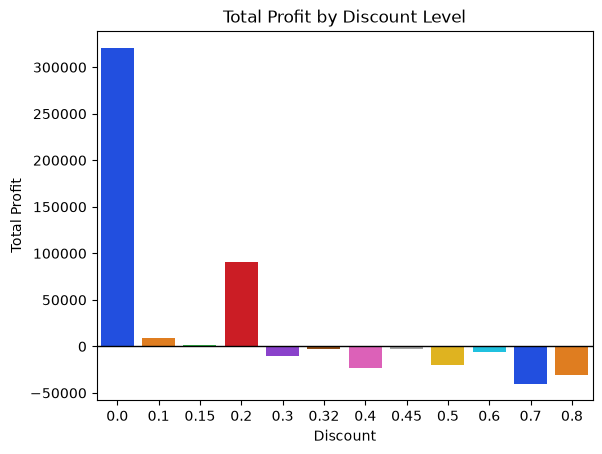

In [70]:
#Total Profit by discount level
discount_analysis= df.groupby('Discount').agg(Total_Sales =('Sales', 'sum'),
                                             Total_profit= ('Profit', 'sum'),
                                             Total_quantity=('Quantity', 'sum'),
                                             No_of_records=('Discount', 'size'))
sns.barplot(x= discount_analysis.index, y= discount_analysis['Total_profit'], palette ='bright')
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.axhline(0, color="black", linewidth=1)

C:\Users\user\AppData\Local\Temp\ipykernel_8408\2799746044.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= avg_pr.index, y= avg_pr.values, palette ='bright')


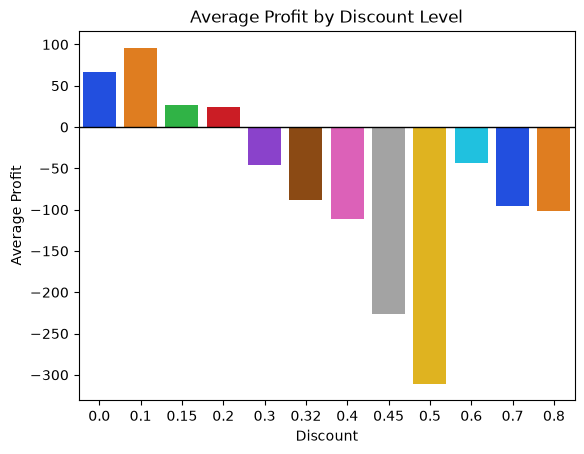

In [71]:
#Average profit by discount level
avg_pr =df.groupby('Discount')['Profit'].mean()
sns.barplot(x= avg_pr.index, y= avg_pr.values, palette ='bright')
plt.title('Average Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.axhline(0, color="black", linewidth=1)

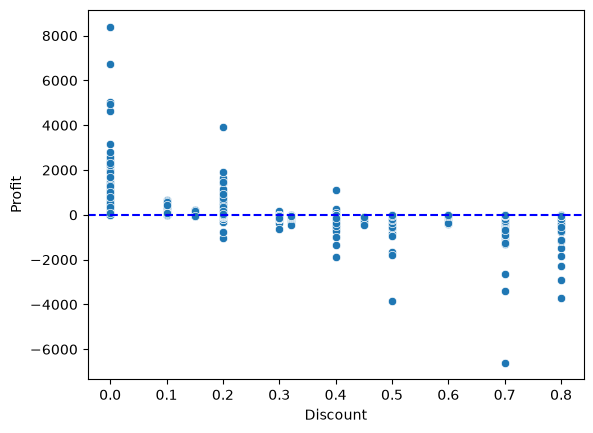

In [72]:
#discount vs Profit
sns.scatterplot(x='Discount', y='Profit', data =df)
plt.axhline(0, color="blue", linestyle="--")

# Key insights from discount Analysis
* Higher discount levels may be associated with lower profitability
* Some discount levels may generate negative total profit
* Products with the same discount can have different profit outcomes

# Order & Shipping Analysis

In [73]:
#sales and profit for each ship mode
ship_analysis = df.groupby('Ship Mode').agg(Total_sales = ('Sales', 'sum'),
                                           Total_Profit=('Profit', 'sum'),
                                           Total_Orders=('Order ID', 'nunique'),
                                           Average_Discount=('Discount', 'mean'))
ship_analysis

,Total_sales,Total_Profit,Total_Orders,Average_Discount
Ship Mode,,,,
First Class,3.514284e+05,48969.8399,787,0.164610
Same Day,1.283631e+05,15891.7589,264,0.152394
Second Class,4.591936e+05,57446.6354,964,0.138895
Standard Class,1.358216e+06,164088.7875,2994,0.160023


In [74]:
#which ship mode generate highest profit
df.groupby('Ship Mode')['Profit'].sum().sort_values(ascending = False).head(1)

Ship Mode
Standard Class    164088.7875
Name: Profit, dtype: float64

# Visualisation

C:\Users\user\AppData\Local\Temp\ipykernel_8408\3761448532.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Ship Mode', palette ='bright')


Text(0, 0.5, 'Number of Records')

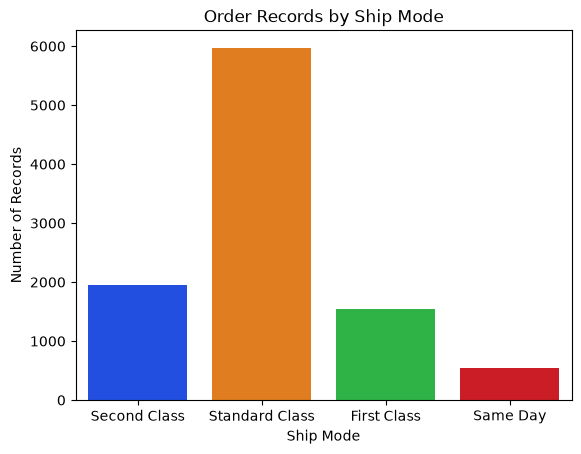

In [75]:
#no of records by ship mode
sns.countplot(data=df, x='Ship Mode', palette ='bright')
plt.title('Order Records by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Number of Records')

C:\Users\user\AppData\Local\Temp\ipykernel_8408\1396837486.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'Ship Mode', y='Profit', estimator = sum, data =df , palette ='bright')


Text(0, 0.5, 'Total Profit')

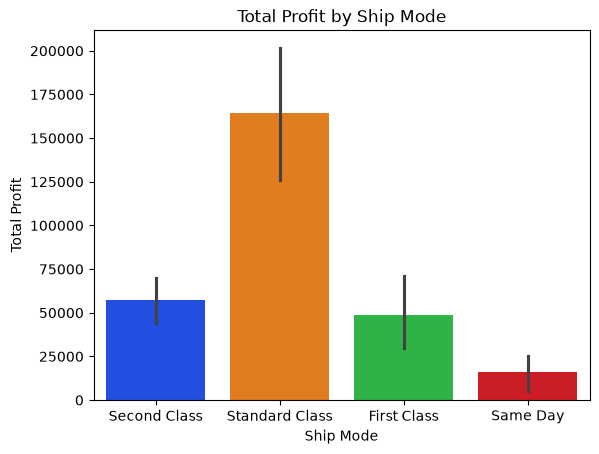

In [76]:
#total profit by ship mode
sns.barplot(x= 'Ship Mode', y='Profit', estimator = sum, data =df , palette ='bright')
plt.title('Total Profit by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Total Profit')

C:\Users\user\AppData\Local\Temp\ipykernel_8408\438633066.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'Ship Mode', y='Sales', estimator = sum, data=df, palette = 'bright')


Text(0, 0.5, 'Total Sales')

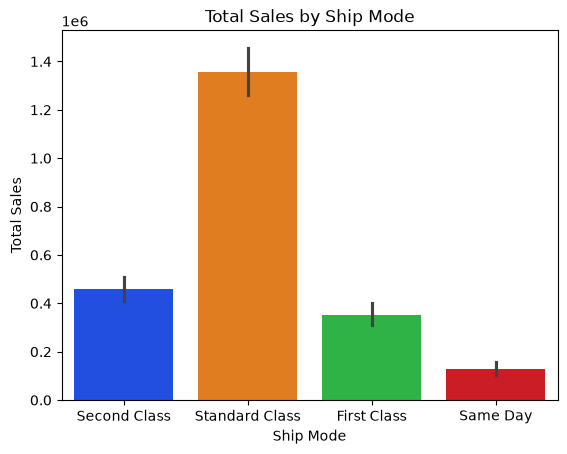

In [77]:
#sales by ship mode
sns.barplot(x= 'Ship Mode', y='Sales', estimator = sum, data=df, palette = 'bright')
plt.title('Total Sales by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Total Sales')

# Key insights from Ship Mode Analysis
* Most frequently used shipping mode is the one with the highest record count
* Ship mode generating the highest total profit contributes the most profit overall
* Total sales and average sales per order measure different aspects of shipping-mode performance


# Statistical Analysis

* Descriptive statistics

In [78]:
columns =['Sales', 'Profit', 'Quantity', 'Discount']
stats = pd.DataFrame({ 'Mean': df[columns].mean(),
                     'Median': df[columns].median(),
                     'Std Deviation': df[columns].std(), 
                     'Minimum': df[columns].min(),
                     'Maximum': df[columns].max()}). round(1)
stats

,Mean,Median,Std Deviation,Minimum,Maximum
Sales,229.9,54.5,623.2,0.4,22638.5
Profit,28.7,8.7,234.3,-6600.0,8400.0
Quantity,3.8,3.0,2.2,1.0,14.0
Discount,0.2,0.2,0.2,0.0,0.8


* Percentiles and quartiles

In [79]:
sales_percentiles = np.percentile(df['Sales'].dropna(),[25, 50, 75])
print("25th Percentile:", round(sales_percentiles[0], 1))
print("50th Percentile:", round(sales_percentiles[1], 1))
print("75th Percentile:", round(sales_percentiles[2], 1))

#These values divide sales observations into four parts:
# 25th percentile: 25% of observations are at or below this value.
# 50th percentile: The median.
# 75th percentile: 75% of observations are at or below this value.

25th Percentile: 17.3
50th Percentile: 54.5
75th Percentile: 209.9


* Correlation analysis

In [80]:
corr = df[['Sales', 'Profit', 'Quantity', 'Discount']].corr()
corr

#A correlation near +1 indicates a strong positive linear relationship.
#A correlation near -1 indicates a strong negative linear relationship.
#A correlation near 0 indicates little or no linear relationship.

,Sales,Profit,Quantity,Discount
Sales,1.000000,0.479064,0.200795,-0.028190
Profit,0.479064,1.000000,0.066253,-0.219487
Quantity,0.200795,0.066253,1.000000,0.008623
Discount,-0.028190,-0.219487,0.008623,1.000000


# Statistical visualizations

<Axes: >

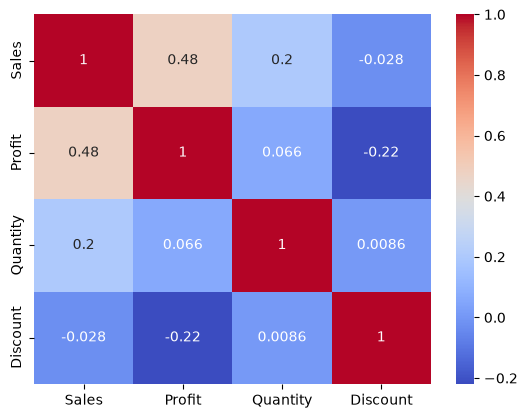

In [87]:
# correlation heatmap Distribution
sns.heatmap(corr, cmap='coolwarm', annot =True)


# Some more Visualisation

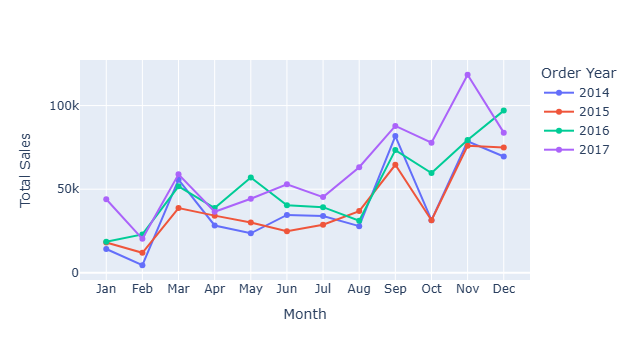

In [82]:
# Monthly sales Trend over year
analysis = df.groupby(['Order Year', 'Order Month'], as_index= False)['Sales'].sum()

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

analysis["Month"] = analysis["Order Month"].map(month_names)


fig= px.line( analysis, x= 'Order Month', y= 'Sales', color= 'Order Year', markers =True, hover_data =['Month'])


fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Total Sales",
    xaxis=dict(
        tickmode="array",
        tickvals=list(range(1, 13)),
        ticktext=list(month_names.values())
    )
)

fig.show()

Text(0, 0.5, 'Profit')

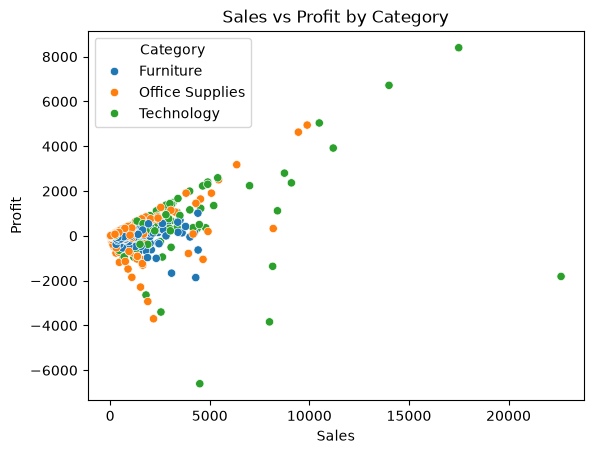

In [83]:
#sales vs profit scatterplot
sns.scatterplot(x='Sales', y='Profit', hue='Category', data= df)
plt.title('Sales vs Profit by Category')
plt.xlabel('Sales')
plt.ylabel('Profit')

# Conclusion & Recommendations
**Key findings**
* Total sales were about $2.30M with a total profit of about $286K.
* Technology is the top category for both sales and profit; Furniture earns the least profit (about $18K) and loses money in the Central region.
* West is the best region; Central has the lowest profit.
* Sales and profit were highest in 2017, and November is the strongest month for sales.
* Discounts of 30% and above lead to negative average profit, while orders with no discount average about +$67 profit per row.
* High sales do not always mean high profit – e.g. the top customer by sales (Sean Miller) has a negative total profit.

**Recommendations**
* Limit discounts to about 20% or less, especially on Furniture.
* Review pricing and discounting of loss-making products (e.g. the Cubify CubeX 3D Printer) and Furniture in the Central region.
* Focus marketing and stock on Technology, the West region and the November peak season.
